In [2]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt


In [20]:
folder_path = r"F:\My Drive\no headstage vids"
prev_file = r"Almog Copies\18L_2025_06_30_14_17_40_stitched_enhancedDLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120"
curr_file = r"18L\18L_2025_06_30_14_17_40_stitched_gammaDLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120"

In [21]:
print(folder_path + '\\' + prev_file + ".h5")

F:\My Drive\no headstage vids\Almog Copies\18L_2025_06_30_14_17_40_stitched_enhancedDLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120.h5


In [22]:
# Read the h5 file, update the path to the raw h5 DLC outputs
h5_prev_file = pd.read_hdf(folder_path + '\\' + prev_file + ".h5")
h5_curr_file = pd.read_hdf(folder_path + '\\' + curr_file + ".h5")

FileNotFoundError: File G:\My Drive\no headstage vids\Almog Copies\18L_2025_06_30_14_17_40_stitched_enhancedDLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120.h5 does not exist

In [108]:
h5_curr_file

scorer    DLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120  \
bodyparts                                                     nose   
coords                                                           x   
0                                                 422.067352         
1                                                 779.644531         
2                                                 783.277710         
3                                                 781.485596         
4                                                 780.463074         
...                                                      ...         
141022                                            303.598328         
141023                                            294.751953         
141024                                            291.269073         
141025                                            295.620026         
141026                                            289.161407         

scorer                                                               \
bodyparts                            midbody                          
coords              y likelihood           x           y likelihood   
0           72.658005   0.122399  432.742279   51.944653   0.424360   
1          280.457428   0.496934  632.890625   81.303947   0.526923   
2          277.816223   0.402064  514.594788  296.627411   0.466751   
3          278.828491   0.462509  514.727966  296.162567   0.471785   
4          280.234680   0.453996  631.995239   83.490417   0.540296   
...               ...        ...         ...         ...        ...   
141022      91.096558   0.427581  294.113190   80.389999   0.453570   
141023      96.937584   0.434780  297.035828   79.540955   0.457766   
141024      94.554749   0.482646  299.790253   78.863091   0.459697   
141025      92.977295   0.423131  300.451935   78.314270   0.497529   
141026      74.310608   0.239963  302.846008   78.585907   0.369931   

scorer                                                                \
bodyparts    tailbase                              ear_R               
coords              x           y likelihood           x           y   
0          442.654175   43.863392   0.334361  430.320496   50.423855   
1          628.964050  118.625473   0.470384  764.680542  274.072754   
2          436.031677   43.506912   0.396759  666.091675  277.598389   
3          528.316162  315.026031   0.374838  765.096619  274.007721   
4          629.606750  118.820793   0.535244  764.840271  274.991089   
...               ...         ...        ...         ...         ...   
141022     291.338348   73.882088   0.302305  292.381470   89.059303   
141023     293.693695   72.254105   0.283101  291.815033   89.010826   
141024     299.809662   71.992241   0.310244  289.282043   84.813293   
141025     297.869110   71.571259   0.304809  292.339233   81.688599   
141026     292.319733   73.452217   0.252299  295.688019   78.459862   

scorer                                                   
bodyparts                  ear_L                         
coords    likelihood           x           y likelihood  
0           0.199774  440.809723   48.301697   0.232343  
1           0.486744  773.203552  265.260315   0.408704  
2           0.376460  678.914429  281.454224   0.284173  
3           0.407232  774.504395  265.299561   0.304153  
4           0.474776  772.441467  265.651489   0.370507  
...              ...         ...         ...        ...  
141022      0.544534  303.359436   82.435219   0.695306  
141023      0.542500  302.875519   86.480888   0.580997  
141024      0.591026  298.880554   87.098877   0.578782  
141025      0.524285  302.005005   82.550903   0.641730  
141026      0.317310  300.992584   83.658600   0.395366  

[141027 rows x 15 columns]

In [23]:
# Update to be the actual file name according to the first index column value of the h5 table
prev_file_name = 'DLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120'
curr_file_name = 'DLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120'

# Load the DataFrame from the HDF5 file
dlc_raw_prev_h5 = h5_prev_file[prev_file_name]
dlc_raw_curr_h5 = h5_curr_file[curr_file_name]

# Extract the MultiIndex from the first two rows
multi_index = pd.MultiIndex.from_arrays([dlc_raw_prev_h5.iloc[0], dlc_raw_prev_h5.iloc[1]])

# Convert the data to numeric, errors='coerce' will turn non-numeric values into NaN
dlc_raw_prev_h5 = dlc_raw_prev_h5.apply(pd.to_numeric, errors='coerce')
dlc_raw_curr_h5 = dlc_raw_curr_h5.apply(pd.to_numeric, errors='coerce')

new_index = pd.MultiIndex.from_tuples([
        ('weighted', 'x'),
        ('weighted', 'y'),
        ('weighted', 'likelihood')
    ])

prev_new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_prev_h5)), columns=new_index)
curr_new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_curr_h5)), columns=new_index)


# Concatenate the original DataFrame with the new columns DataFrame
# dlc_raw_h5 = pd.concat([dlc_raw_h5, new_columns], axis=1)

dlc_raw_prev_h5 = pd.concat([dlc_raw_prev_h5, prev_new_index_df], axis=1)
dlc_raw_curr_h5 = pd.concat([dlc_raw_curr_h5, curr_new_index_df], axis=1)

dlc_raw_prev_h5


nose                           midbody                        \
                x          y likelihood           x          y likelihood   
0       34.466011  57.775776   0.123587  433.405823  51.065639   0.479889   
1       34.007965  58.352337   0.140160  433.354553  51.097836   0.496480   
2       34.215561  58.379032   0.128277  433.670685  50.193363   0.496837   
3       33.931305  58.177242   0.152120  433.717529  50.308697   0.496232   
4       33.942253  58.244209   0.144659  433.575806  50.549118   0.486234   
...           ...        ...        ...         ...        ...        ...   
104318  45.923782  56.261417   0.840662   55.134937  92.841042   0.668337   
104319  45.826870  56.279987   0.839751   55.142822  92.850800   0.666981   
104320  45.857147  56.310211   0.842030   55.167709  92.826019   0.667612   
104321  45.846119  56.311462   0.842277   55.147366  92.840927   0.668559   
104322  46.176762  56.327766   0.857573   55.175461  92.869225   0.661829   

          tailbase                              ear_R                         \
                 x           y likelihood           x           y likelihood   
0       443.087219   42.442627   0.346734   48.251602  524.205811   0.183992   
1       443.133453   42.205349   0.333117  424.196869   50.403881   0.160883   
2       443.150360   42.124771   0.335919  424.003479   50.265167   0.167429   
3       443.162262   42.038605   0.334886   50.798790  325.095947   0.171263   
4       442.847931   42.523289   0.317466   50.520863  324.792328   0.172650   
...            ...         ...        ...         ...         ...        ...   
104318   59.899479  105.474342   0.321143   57.878380   72.433342   0.809707   
104319   60.058353  105.434654   0.318418   57.867401   72.404465   0.813056   
104320   59.981720  105.485397   0.319425   57.896164   72.420189   0.812530   
104321   59.975445  105.451904   0.319099   57.879257   72.374931   0.812908   
104322   60.060555  105.322235   0.316257   57.867039   72.512245   0.812140   

             ear_L                       weighted                 
                 x          y likelihood        x   y likelihood  
0       440.969452  47.700050   0.204784      NaN NaN        NaN  
1       441.109772  47.440685   0.203589      NaN NaN        NaN  
2       441.207001  47.467529   0.213309      NaN NaN        NaN  
3       441.173645  47.368633   0.210768      NaN NaN        NaN  
4       441.201324  47.705875   0.204332      NaN NaN        NaN  
...            ...        ...        ...      ...  ..        ...  
104318   43.285984  75.207214   0.664694      NaN NaN        NaN  
104319   43.267246  75.178268   0.666828      NaN NaN        NaN  
104320   43.306877  75.209816   0.665816      NaN NaN        NaN  
104321   43.303448  75.172905   0.667310      NaN NaN        NaN  
104322   43.526230  75.272560   0.671827      NaN NaN        NaN  

[104323 rows x 18 columns]

In [24]:
dlc_raw_curr_h5

nose                            midbody                         \
                 x           y likelihood           x           y likelihood   
0       422.067352   72.658005   0.122399  432.742279   51.944653   0.424360   
1       779.644531  280.457428   0.496934  632.890625   81.303947   0.526923   
2       783.277710  277.816223   0.402064  514.594788  296.627411   0.466751   
3       781.485596  278.828491   0.462509  514.727966  296.162567   0.471785   
4       780.463074  280.234680   0.453996  631.995239   83.490417   0.540296   
...            ...         ...        ...         ...         ...        ...   
141022  303.598328   91.096558   0.427581  294.113190   80.389999   0.453570   
141023  294.751953   96.937584   0.434780  297.035828   79.540955   0.457766   
141024  291.269073   94.554749   0.482646  299.790253   78.863091   0.459697   
141025  295.620026   92.977295   0.423131  300.451935   78.314270   0.497529   
141026  289.161407   74.310608   0.239963  302.846008   78.585907   0.369931   

          tailbase                              ear_R                         \
                 x           y likelihood           x           y likelihood   
0       442.654175   43.863392   0.334361  430.320496   50.423855   0.199774   
1       628.964050  118.625473   0.470384  764.680542  274.072754   0.486744   
2       436.031677   43.506912   0.396759  666.091675  277.598389   0.376460   
3       528.316162  315.026031   0.374838  765.096619  274.007721   0.407232   
4       629.606750  118.820793   0.535244  764.840271  274.991089   0.474776   
...            ...         ...        ...         ...         ...        ...   
141022  291.338348   73.882088   0.302305  292.381470   89.059303   0.544534   
141023  293.693695   72.254105   0.283101  291.815033   89.010826   0.542500   
141024  299.809662   71.992241   0.310244  289.282043   84.813293   0.591026   
141025  297.869110   71.571259   0.304809  292.339233   81.688599   0.524285   
141026  292.319733   73.452217   0.252299  295.688019   78.459862   0.317310   

             ear_L                        weighted                 
                 x           y likelihood        x   y likelihood  
0       440.809723   48.301697   0.232343      NaN NaN        NaN  
1       773.203552  265.260315   0.408704      NaN NaN        NaN  
2       678.914429  281.454224   0.284173      NaN NaN        NaN  
3       774.504395  265.299561   0.304153      NaN NaN        NaN  
4       772.441467  265.651489   0.370507      NaN NaN        NaN  
...            ...         ...        ...      ...  ..        ...  
141022  303.359436   82.435219   0.695306      NaN NaN        NaN  
141023  302.875519   86.480888   0.580997      NaN NaN        NaN  
141024  298.880554   87.098877   0.578782      NaN NaN        NaN  
141025  302.005005   82.550903   0.641730      NaN NaN        NaN  
141026  300.992584   83.658600   0.395366      NaN NaN        NaN  

[141027 rows x 18 columns]

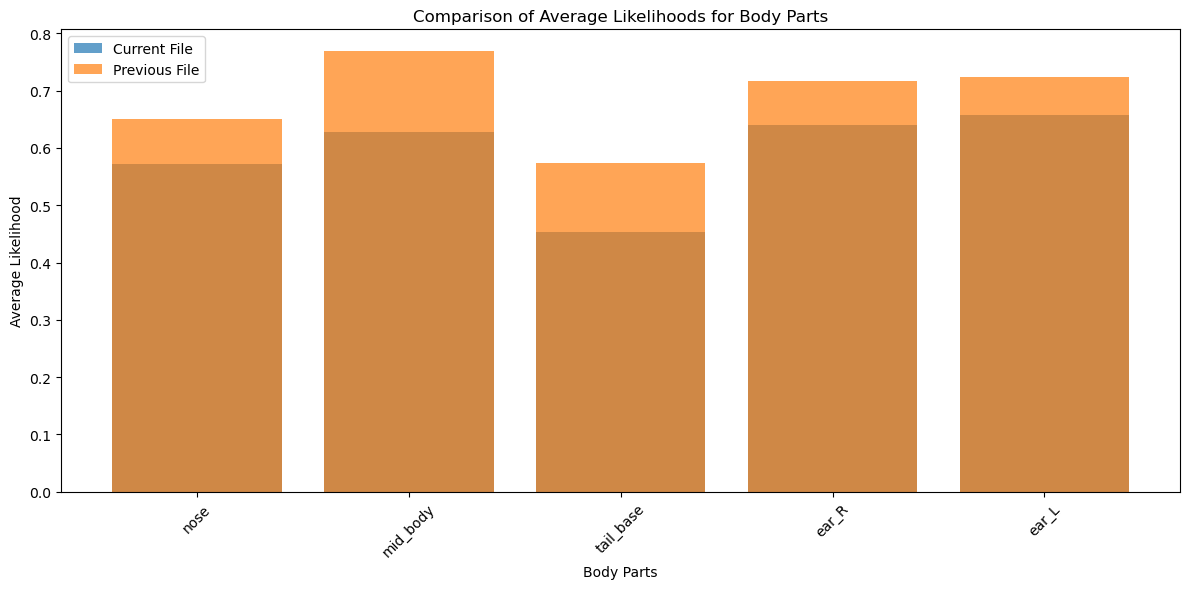

In [25]:
# Extract likelihood columns for both datasets
curr_likelihoods = dlc_raw_curr_h5.xs('likelihood', level=1, axis=1)
prev_likelihoods = dlc_raw_prev_h5.xs('likelihood', level=1, axis=1)

# Drop the 'weighted' column from both datasets
curr_likelihoods = curr_likelihoods.drop(columns=['weighted'])
prev_likelihoods = prev_likelihoods.drop(columns=['weighted'])

# Rename columns to merge names with '_'
curr_likelihoods.columns = curr_likelihoods.columns.str.replace('midbody', 'mid_body').str.replace('tailbase', 'tail_base')
prev_likelihoods.columns = prev_likelihoods.columns.str.replace('midbody', 'mid_body').str.replace('tailbase', 'tail_base')
# Calculate average likelihoods for each body part
curr_avg_likelihoods = curr_likelihoods.mean()
prev_avg_likelihoods = prev_likelihoods.mean()

# Plot the average likelihoods for comparison
plt.figure(figsize=(12, 6))
plt.bar(curr_avg_likelihoods.index, curr_avg_likelihoods, alpha=0.7, label='Current File')
plt.bar(prev_avg_likelihoods.index, prev_avg_likelihoods, alpha=0.7, label='Previous File')
plt.xlabel('Body Parts')
plt.ylabel('Average Likelihood')
plt.title('Comparison of Average Likelihoods for Body Parts')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

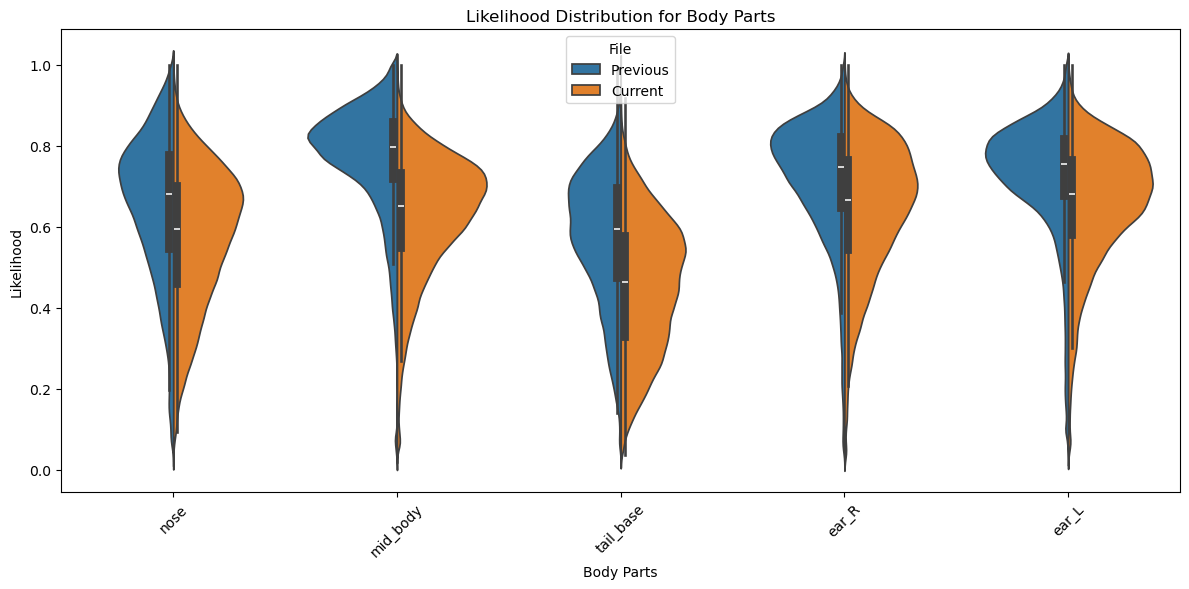

In [26]:
import seaborn as sns

# Combine the likelihood data into a single DataFrame for plotting
combined_likelihoods = pd.concat([
    prev_likelihoods.melt(var_name='Body Part', value_name='Likelihood').assign(File='Previous'),
    curr_likelihoods.melt(var_name='Body Part', value_name='Likelihood').assign(File='Current')
])

# Create the violin plot
plt.figure(figsize=(12, 6))
sns.violinplot(data=combined_likelihoods, x='Body Part', y='Likelihood', hue='File', split=True)
plt.title('Likelihood Distribution for Body Parts')
plt.xlabel('Body Parts')
plt.ylabel('Likelihood')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [65]:
from itertools import combinations

# Define bodyparts to check
bodyparts = ['nose', 'midbody', 'tailbase', 'ear_R', 'ear_L']

# 1. Inter-bodypart distance outlier detection
# Calculate average distance between each pair of bodyparts across all frames

# Get coordinates for each bodypart
coords = {bp: np.stack([dlc_raw_curr_h5[(bp, 'x')], dlc_raw_curr_h5[(bp, 'y')]], axis=1) for bp in bodyparts}

# Compute mean distance for each pair
pairwise_means = {}
pairwise_medians = {}
for bp1, bp2 in combinations(bodyparts, 2):
    dists = np.linalg.norm(coords[bp1] - coords[bp2], axis=1)
    pairwise_means[(bp1, bp2)] = dists.mean()
    pairwise_medians[(bp1, bp2)] = np.median(dists)  # Using median for more robust outlier detection

# For each frame, check if any pair is > 3x median distance
# outlier_matrix_dist = pd.DataFrame(False, index=dlc_raw_curr_h5.index, columns=bodyparts)
# for bp1, bp2 in combinations(bodyparts, 2):
#     dists = np.linalg.norm(coords[bp1] - coords[bp2], axis=1)
#     outlier_frames = dists > 3 * pairwise_medians[(bp1, bp2)]
#     # Mark both bodyparts as outlier in these frames
#     outlier_matrix_dist.loc[outlier_frames, bp1] = True
#     outlier_matrix_dist.loc[outlier_frames, bp2] = True

# 2. Jump outlier detection (frame-to-frame movement)
# outlier_matrix_jump = pd.DataFrame(False, index=dlc_raw_curr_h5.index, columns=bodyparts)
# for bp in bodyparts:
#     xy = coords[bp]
#     jumps = np.linalg.norm(xy[1:] - xy[:-1], axis=1)
#     mean_jump = jumps.mean()
#     median_jump = np.median(jumps)
#     max_jump = jumps.max()
#     # Outlier if jump > 3 times median jump
#     outlier_idx = np.where(jumps > median_jump * 3)[0] + 1  # +1 because jump is from frame i-1 to i
#     outlier_matrix_jump.loc[outlier_idx, bp] = True

# Combine both outlier matrices
# outlier_matrix = outlier_matrix_dist | outlier_matrix_jump

expected_means_dist = {}
for bp in bodyparts:
    # For each frame, compute mean distance from bp to all others
    dists = []
    for i in range(len(dlc_raw_curr_h5)):
        others = [other for other in bodyparts if other != bp]
        d = [np.linalg.norm(coords[bp][i] - coords[other][i]) for other in others]
        dists.append(np.mean(d))
    expected_means_dist[bp] = np.median(dists)

# For each frame, check which bodyparts are outliers
outlier_bodyparts = []
for i in range(len(dlc_raw_curr_h5)):
    frame_outliers = []
    for bp in bodyparts:
        others = [other for other in bodyparts if other != bp]
        d = [np.linalg.norm(coords[bp][i] - coords[other][i]) for other in others]
        mean_dist = np.median(d)
        # if i == 2159:
        #     print(f"Frame {i}, Bodypart {bp}, Mean Distance: {mean_dist}, Expected Mean: {expected_means_dist[bp]}")
        if mean_dist > 3 * expected_means_dist[bp]:
            frame_outliers.append(bp)
    outlier_bodyparts.append(frame_outliers)

# Add the list of outlier bodyparts as a new column
dlc_raw_curr_h5['distance_outlier_bodyparts'] = outlier_bodyparts

expected_means_jump = {}
for bp in bodyparts:
    xy = coords[bp]
    # Calculate frame-to-frame jumps
    jumps = np.linalg.norm(xy[1:] - xy[:-1], axis=1)
    # Use 90th percentile instead of median for expected jump
    expected_means_jump[bp] = np.percentile(jumps, 90)
    # expected_means_jump[bp] = np.median(jumps)

jumps_outlier_bodypart = []
for i in range(len(dlc_raw_curr_h5)):
    frame_outliers = []
    for bp in bodyparts:
        xy = coords[bp]
        if i == 0:
            continue  # No previous frame to compare
        jump = np.linalg.norm(xy[i] - xy[i-1])
        if jump > 8 * expected_means_jump[bp]:
            frame_outliers.append(bp)
    jumps_outlier_bodypart.append(frame_outliers)

# Pad the first frame with empty list (since no jump possible)
# jumps_outlier_bodypart = [[]] + jumps_outlier_bodypart

dlc_raw_curr_h5['jumps_outlier_bodypart'] = jumps_outlier_bodypart


# Example: Show frames with any outlier
print(dlc_raw_curr_h5[dlc_raw_curr_h5['distance_outlier_bodyparts'].apply(len) > 0][['distance_outlier_bodyparts']].head())

# Show summary of outliers per bodypart
# outlier_counts = outlier_matrix.sum()
# print("Outlier counts per bodypart:")
# print(outlier_counts)

# Optionally, show frames with any outlier
# outlier_frames = outlier_matrix.any(axis=1)
# print(f"Total frames with any outlier: {outlier_frames.sum()}")

# print("Total frames in dataset:", len(dlc_raw_curr_h5))

# outlier_matrix is a DataFrame (frames x bodyparts) with True for outlier labels

                distance_outlier_bodyparts
                                          
1  [nose, midbody, tailbase, ear_R, ear_L]
2  [nose, midbody, tailbase, ear_R, ear_L]
3  [nose, midbody, tailbase, ear_R, ear_L]
4  [nose, midbody, tailbase, ear_R, ear_L]
5  [nose, midbody, tailbase, ear_R, ear_L]


In [27]:
output_tifs_folder = r"F:\Shared drives\FinkelsteinLab\People\AlmogMeir\DLC_Tests"

In [129]:
expected_means_dist

{'nose': 29.339226,
 'midbody': 23.027607,
 'tailbase': 35.32243,
 'ear_R': 21.780092,
 'ear_L': 21.162086}

In [87]:
expected_means_jump

8.60665740966797

In [29]:
outlier_frames = dlc_raw_curr_h5[dlc_raw_curr_h5['distance_outlier_bodyparts'].apply(len) > 0]
outlier_frames

nose                            midbody                         \
                 x           y likelihood           x           y likelihood   
1       779.644531  280.457428   0.496934  632.890625   81.303947   0.526923   
2       783.277710  277.816223   0.402064  514.594788  296.627411   0.466751   
3       781.485596  278.828491   0.462509  514.727966  296.162567   0.471785   
4       780.463074  280.234680   0.453996  631.995239   83.490417   0.540296   
5       782.234924  278.829773   0.417450  630.712341   88.633469   0.343812   
...            ...         ...        ...         ...         ...        ...   
139882  193.300278  247.008743   0.287550  150.104431  688.972900   0.271434   
139883  193.513824  245.610931   0.329554  150.282211  688.872620   0.304528   
139941  177.230011  255.571609   0.456356  194.293686  242.071625   0.367050   
139942  170.190598  255.233368   0.402989  184.756119  245.913498   0.362258   
140989  287.269348   85.901802   0.131041  380.666962  298.723267   0.100032   

          tailbase                              ear_R                         \
                 x           y likelihood           x           y likelihood   
1       628.964050  118.625473   0.470384  764.680542  274.072754   0.486744   
2       436.031677   43.506912   0.396759  666.091675  277.598389   0.376460   
3       528.316162  315.026031   0.374838  765.096619  274.007721   0.407232   
4       629.606750  118.820793   0.535244  764.840271  274.991089   0.474776   
5       629.068420  121.366051   0.455095  764.702698  275.326843   0.391379   
...            ...         ...        ...         ...         ...        ...   
139882  202.929642  201.431656   0.211404  190.970779  227.656418   0.285650   
139883  144.456024  695.920410   0.228072  193.497955  228.726456   0.294999   
139941  141.840088  689.422668   0.169706  173.816101  242.943146   0.510089   
139942  144.006256  694.627136   0.183451  169.791107  248.174850   0.416362   
140989  293.820740   82.775002   0.142434  289.320221   72.040070   0.139907   

             ear_L                        weighted                 \
                 x           y likelihood        x   y likelihood   
1       773.203552  265.260315   0.408704      NaN NaN        NaN   
2       678.914429  281.454224   0.284173      NaN NaN        NaN   
3       774.504395  265.299561   0.304153      NaN NaN        NaN   
4       772.441467  265.651489   0.370507      NaN NaN        NaN   
5       772.619446  265.118134   0.291367      NaN NaN        NaN   
...            ...         ...        ...      ...  ..        ...   
139882  197.059967  232.808350   0.361514      NaN NaN        NaN   
139883  198.562378  232.274033   0.360489      NaN NaN        NaN   
139941  187.559799  247.063065   0.639856      NaN NaN        NaN   
139942  183.401596  243.531082   0.609999      NaN NaN        NaN   
140989  288.157593   83.418182   0.134902      NaN NaN        NaN   

                     distance_outlier_bodyparts  \
                                                  
1       [nose, midbody, tailbase, ear_R, ear_L]   
2       [nose, midbody, tailbase, ear_R, ear_L]   
3       [nose, midbody, tailbase, ear_R, ear_L]   
4       [nose, midbody, tailbase, ear_R, ear_L]   
5       [nose, midbody, tailbase, ear_R, ear_L]   
...                                         ...   
139882                                [midbody]   
139883  [nose, midbody, tailbase, ear_R, ear_L]   
139941                               [tailbase]   
139942                               [tailbase]   
140989                                [midbody]   

                         jumps_outlier_bodypart  
                                                 
1       [nose, midbody, tailbase, ear_R, ear_L]  
2             [midbody, tailbase, ear_R, ear_L]  
3                      [tailbase, ear_R, ear_L]  
4                           [midbody, tailbase]  
5                                            []  
...                 

In [69]:
outlier_frames_jumps = dlc_raw_curr_h5[dlc_raw_curr_h5['jumps_outlier_bodypart'].apply(len) > 0]
outlier_frames_jumps[1020:]

nose                            midbody                         \
                 x           y likelihood           x           y likelihood   
23804   269.150208  640.674744   0.292333  295.662628  648.692017   0.420493   
23805   272.350433  646.073181   0.313625  307.210846  648.008972   0.315281   
23806   346.530853  641.863770   0.318010  309.368652  647.756897   0.407323   
23808   280.090454  648.795959   0.315128  315.931732  649.083008   0.601590   
23809   360.332550  637.601013   0.251416  320.905731  646.234497   0.435253   
...            ...         ...        ...         ...         ...        ...   
140649  308.084625  167.156250   0.248502  280.949951  166.484436   0.550942   
140651  266.673645  168.109222   0.184327  292.923553  165.721176   0.521675   
140655  342.203644  162.356033   0.429114  310.407043  163.969711   0.596683   
140989  287.269348   85.901802   0.131041  380.666962  298.723267   0.100032   
140990  287.217865   67.889412   0.202841  288.678253   81.949005   0.131067   

          tailbase                              ear_R                         \
                 x           y likelihood           x           y likelihood   
23804   330.916718  645.919678   0.186544  279.992554  643.378357   0.392468   
23805   333.225525  644.770874   0.130402  332.895691  651.642517   0.381291   
23806   336.879120  643.033203   0.133295  337.813202  650.537842   0.458694   
23808   284.903320  649.021667   0.393725  347.931305  649.476746   0.408389   
23809   292.058319  649.306091   0.376739  352.609283  650.182800   0.380462   
...            ...         ...        ...         ...         ...        ...   
140649  266.037506  169.059326   0.333118  296.557556  167.619110   0.309150   
140651  316.928772  165.974426   0.358590  278.418518  163.095734   0.236835   
140655  291.036652  167.011734   0.307935  331.329834  166.884293   0.455610   
140989  293.820740   82.775002   0.142434  289.320221   72.040070   0.139907   
140990  294.209778   79.798950   0.183084  289.130035   72.733795   0.171560   

             ear_L                        weighted                 \
                 x           y likelihood        x   y likelihood   
23804   273.506195  646.831543   0.417983      NaN NaN        NaN   
23805   282.932037  655.184448   0.287856      NaN NaN        NaN   
23806   333.687561  644.737854   0.388388      NaN NaN        NaN   
23808   342.337128  641.205078   0.347016      NaN NaN        NaN   
23809   343.976746  641.659790   0.311306      NaN NaN        NaN   
...            ...         ...        ...      ...  ..        ...   
140649  299.520844  161.462692   0.379071      NaN NaN        NaN   
140651  303.729248  164.302124   0.221846      NaN NaN        NaN   
140655  330.681854  159.515594   0.574837      NaN NaN        NaN   
140989  288.157593   83.418182   0.134902      NaN NaN        NaN   
140990  285.635437   71.342430   0.177395      NaN NaN        NaN   

       distance_outlier_bodyparts jumps_outlier_bodypart  
                                                          
23804                          []         [ear_R, ear_L]  
23805                          []                [ear_R]  
23806                          []          [nose, ear_L]  
23808                          []       [nose, tailbase]  
23809                          []                 [nose]  
...                           ...                    ...  
140649                         []                 [nose]  
140651                         []                 [nose]  
140655                         []                 [nose]  
140989                  [midbody]              [midbody]  
140990                         []              [midbody]  

[2093 rows x 20 columns]

In [ ]:
# print("nose coords 2159:", coords['nose'][2159])
# others = [other for other in bodyparts if other != 'nose']
# d = [np.linalg.norm(coords['nose'][i] - coords[other][i]) for other in others]
# print("Distances from nose to others at frame 2159:", d)
# mean_dist = np.mean(d)
# print("Mean distance from nose to others at frame 2159:", mean_dist)

nose coords 2159: [  1.9014711 733.14197  ]
Distances from nose to others at frame 2159: [41.652664, 60.466244, 22.87461, 21.084583]
Mean distance from nose to others at frame 2159: 36.519527


In [84]:
from collections import Counter

# Find sequences of consecutive frames with any outlier
outlier_bool = outlier_frames.values  # Convert to numpy array for efficient processing

# Find the start and end indices of each sequence
diff = np.diff(outlier_bool.astype(int))
starts = np.where(diff == 1)[0] + 1 if outlier_bool[0] == False else np.insert(np.where(diff == 1)[0] + 1, 0, 0)
ends = np.where(diff == -1)[0] + 1 if outlier_bool[-1] == False else np.append(np.where(diff == -1)[0] + 1, len(outlier_bool))

# If the first frame is an outlier, ensure the first sequence starts at 0
if outlier_bool[0]:
    starts = np.insert(starts, 0, 0)
# If the last frame is an outlier, ensure the last sequence ends at the last index
if outlier_bool[-1]:
    ends = np.append(ends, len(outlier_bool))

# Calculate sequence lengths
seq_lengths = ends - starts

# Count the number of sequences for each length
length_counts = Counter(seq_lengths)

# Convert to DataFrame for easier viewing (optional)
seq_length_df = pd.DataFrame.from_dict(length_counts, orient='index', columns=['count']).sort_index()
seq_length_df.index.name = 'sequence_length'
seq_length_df

,count
sequence_length,
3,195
4,214
5,261
6,213
7,170
...,...
716,1
798,1
885,1


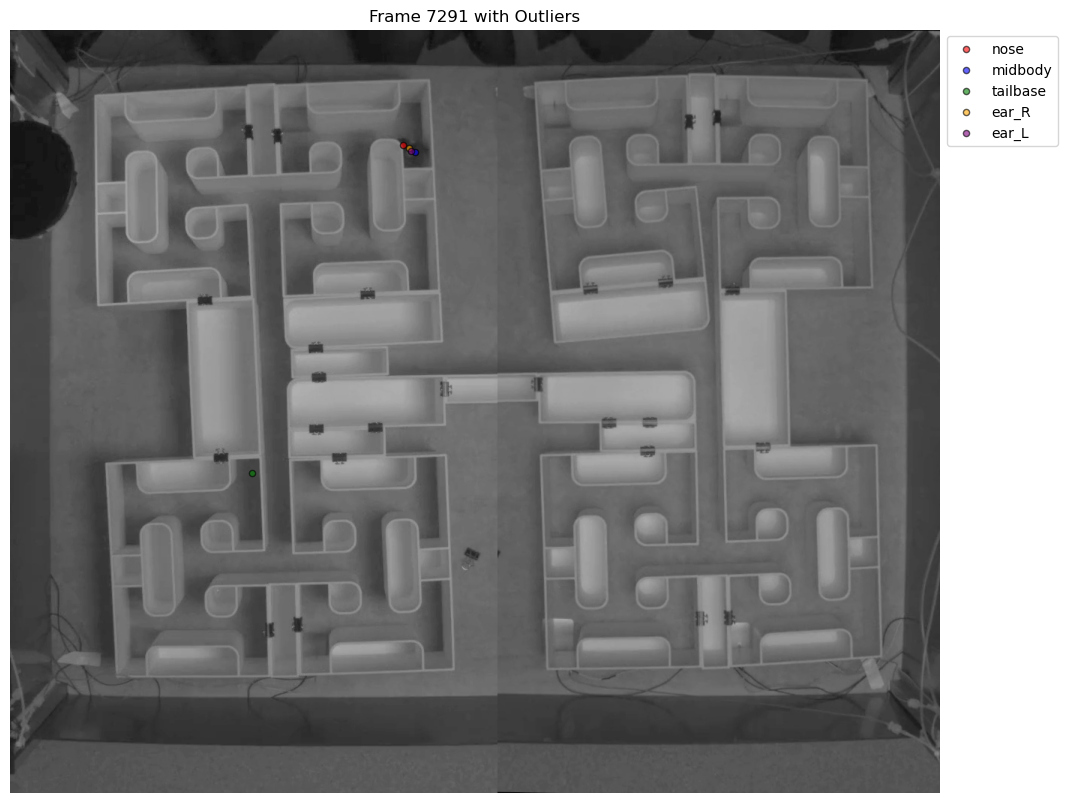

In [44]:
import cv2
# Prepare color map for bodyparts
color_map = {
    'nose': 'red',
    'midbody': 'blue',
    'tailbase': 'green',
    'ear_R': 'orange',
    'ear_L': 'purple'
}

# Find the n frame index with any outlier in the dist matrix
outlier_idx = int(outlier_frames.iloc[1000].name)
# outlier_idx = 2097
# 2845 - 2895

# Read the video file (assume video file is in the same folder and named after curr_file, with .mp4 extension)
video_path = r"F:\My Drive\no headstage vids\18L\18L_2025_06_30_14_17_40_stitched_gamma.mp4"
cap = cv2.VideoCapture(video_path)

# Get the frame at outlier_idx (assuming outlier_idx matches video frame index)
cap.set(cv2.CAP_PROP_POS_FRAMES, outlier_idx)
ret, frame_img = cap.read()
cap.release()

if not ret:
    raise RuntimeError(f"Could not read frame {outlier_idx} from {video_path}")

# Convert BGR (OpenCV) to RGB (matplotlib)
frame_img = cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB)
# Remove bodypart text, only plot colored dots.

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 12))
plt.imshow(frame_img)
# Adjust for cropping by subtracting x1 and y1 from the coordinates
crop_x1, crop_y1 = 100, 60

for bp in bodyparts:
    x = dlc_raw_curr_h5.loc[outlier_idx, (bp, 'x')] + crop_x1
    y = dlc_raw_curr_h5.loc[outlier_idx, (bp, 'y')] + crop_y1
    plt.scatter(x, y, color=color_map[bp], marker='.', s=80, label=bp, edgecolor='black', alpha=0.6)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.axis('off')
plt.title(f"Frame {outlier_idx} with Outliers")
plt.show()


In [63]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

def save_outlier_tifs(
    outlier_df, dlc_df, video_path, bodyparts, color_map, crop_x1=0, crop_y1=0,
    output_folder=r"F:\Shared drives\FinkelsteinLab\People\AlmogMeir\DLC_Tests\distance_outliers",
    start_idx=0, end_idx=None
):
    os.makedirs(output_folder, exist_ok=True)
    cap = cv2.VideoCapture(video_path)
    indices = list(outlier_df.index)
    if end_idx is None:
        end_idx = len(indices)
    for idx in indices[start_idx:end_idx]:
        frame = idx
        # Read frame
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame)
        ret, frame_img = cap.read()
        if not ret:
            print(f"Could not read frame {frame}")
            continue
        frame_img = cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB)

        # Plot
        fig, ax = plt.subplots(figsize=(12, 12))
        ax.imshow(frame_img)
        for bp in bodyparts:
            x = dlc_df.loc[frame, (bp, 'x')] + crop_x1
            y = dlc_df.loc[frame, (bp, 'y')] + crop_y1
            ax.scatter(x, y, color=color_map[bp], marker='.', s=80, label=bp, edgecolor='black', alpha=0.6)
        ax.legend(loc='upper left', bbox_to_anchor=(1, 1))

        # Outlier bodyparts
        outlier_bps = outlier_df.loc[frame, 'distance_outlier_bodyparts']
        if isinstance(outlier_bps, pd.Series):
            outlier_bps = outlier_bps.iloc[0]

        # Calculate median distances for outlier bodyparts
        hist_data = {}
        for bp in outlier_bps:
            dists = []
            for offset in range(-5, 6):
                f = frame + offset
                if f < 0 or f >= len(dlc_df):
                    continue
                others = [other for other in bodyparts if other != bp]
                d = [np.linalg.norm([
                    dlc_df.loc[f, (bp, 'x')] - dlc_df.loc[f, (other, 'x')],
                    dlc_df.loc[f, (bp, 'y')] - dlc_df.loc[f, (other, 'y')]
                ]) for other in others]
                dists.append(np.median(d))
            hist_data[bp] = dists

        # Metrics text
        info_text = f"Frame: {frame}\nOutlier(s): {', '.join(outlier_bps) if len(outlier_bps) > 0 else 'None'}"
        ax.text(
            1.05, 0.6, info_text, transform=ax.transAxes,
            fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
        )

                # Calculate median distances for outlier bodyparts
        hist_data = {}
        for bp in outlier_bps:
            dists = []
            for offset in range(-10, 11):  # -10 to +10
                f = frame + offset
                if f < 0 or f >= len(dlc_df):
                    dists.append(np.nan)
                    continue
                others = [other for other in bodyparts if other != bp]
                d = [np.linalg.norm([
                    dlc_df.loc[f, (bp, 'x')] - dlc_df.loc[f, (other, 'x')],
                    dlc_df.loc[f, (bp, 'y')] - dlc_df.loc[f, (other, 'y')]
                ]) for other in others]
                dists.append(np.median(d))
            hist_data[bp] = dists

        # Metrics text
        info_text = f"Frame: {frame}\nOutlier(s): {', '.join(outlier_bps) if len(outlier_bps) > 0 else 'None'}"
        ax.text(
            1.05, 0.6, info_text, transform=ax.transAxes,
            fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
        )

        # Plot histogram for each outlier bodypart (to the left, smaller y axis)
        if hist_data:
            ax_hist = fig.add_axes([0.85, 0.1, 0.18, 0.15])  # [left, bottom, width, height]
            offsets = list(range(-10, 11))
            for bp, dists in hist_data.items():
                ax_hist.plot(offsets, dists, marker='o', label=bp, color=color_map[bp])
            ax_hist.set_title("Median dists\n(-10:0:+10)")
            ax_hist.set_xlabel("Frame offset")
            ax_hist.set_ylabel("Median dist")
            ax_hist.legend(fontsize=8)
            ax_hist.grid(True)
            # Optionally, set a fixed y-limit for better appearance:
            # ax_hist.set_ylim(bottom=0, top=20)

        ax.axis('off')
        ax.set_title(f"Frame {frame} with Outliers")
        plt.tight_layout()
        plt.savefig(os.path.join(output_folder, f"outlier_frame_{frame}.tif"), dpi=100, bbox_inches='tight')
        plt.close(fig)

# Example usage:
save_outlier_tifs(outlier_frames, dlc_raw_curr_h5, video_path, bodyparts, color_map, crop_x1=100, crop_y1=60, start_idx=1020)

C:\Users\Almog\AppData\Local\Temp\ipykernel_26724\566958210.py:103: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


In [71]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

def save_outlier_tifs(
    outlier_df, dlc_df, video_path, bodyparts, color_map, crop_x1=0, crop_y1=0,
    output_folder=r"F:\Shared drives\FinkelsteinLab\People\AlmogMeir\DLC_Tests\distance_outliers",
    start_idx=0, end_idx=None
):
    os.makedirs(output_folder, exist_ok=True)
    cap = cv2.VideoCapture(video_path)
    indices = list(outlier_df.index)
    if end_idx is None:
        end_idx = len(indices)
    for idx in indices[start_idx:end_idx]:
        frame = idx
        # Read frame
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame)
        ret, frame_img = cap.read()
        if not ret:
            print(f"Could not read frame {frame}")
            continue
        frame_img = cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB)

 # Plot
        fig, ax = plt.subplots(figsize=(12, 12))
        ax.imshow(frame_img)
        legend_labels = []
        legend_handles = []
        for bp in bodyparts:
            x = dlc_df.loc[frame, (bp, 'x')] + crop_x1
            y = dlc_df.loc[frame, (bp, 'y')] + crop_y1
            likelihood = dlc_df.loc[frame, (bp, 'likelihood')]
            label = f"{bp} (L={likelihood:.2f})"
            sc = ax.scatter(x, y, color=color_map[bp], marker='.', s=80, label=label, edgecolor='black', alpha=0.6)
            legend_labels.append(label)
            legend_handles.append(sc)
        ax.legend(legend_handles, legend_labels, loc='upper left', bbox_to_anchor=(1, 1))

        # Outlier bodyparts
        outlier_bps = outlier_df.loc[frame, 'distance_outlier_bodyparts']
        if isinstance(outlier_bps, pd.Series):
            outlier_bps = outlier_bps.iloc[0]

        # Calculate median distances for outlier bodyparts
        hist_data = {}
        for bp in outlier_bps:
            dists = []
            for offset in range(-10, 11):  # -10 to +10
                f = frame + offset
                if f < 0 or f >= len(dlc_df):
                    dists.append(np.nan)
                    continue
                others = [other for other in bodyparts if other != bp]
                d = [np.linalg.norm([
                    dlc_df.loc[f, (bp, 'x')] - dlc_df.loc[f, (other, 'x')],
                    dlc_df.loc[f, (bp, 'y')] - dlc_df.loc[f, (other, 'y')]
                ]) for other in others]
                dists.append(np.median(d))
            hist_data[bp] = dists

        # Metrics text
        info_text = f"Frame: {frame}\nOutlier(s): {', '.join(outlier_bps) if len(outlier_bps) > 0 else 'None'}"
        ax.text(
            1.05, 0.6, info_text, transform=ax.transAxes,
            fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
        )

        # Plot histogram for each outlier bodypart (to the right, smaller y axis)
        if hist_data:
            ax_hist = fig.add_axes([0.78, 0.1, 0.18, 0.4])  # [left, bottom, width, height]
            offsets = list(range(-10, 11))
            for bp, dists in hist_data.items():
                ax_hist.plot(offsets, dists, marker='o', label=bp, color=color_map[bp])
                # Add expected_mean distance as dashed line
                if 'expected_means_dist' in globals():
                    expected = expected_means_dist.get(bp, None)
                    if expected is not None:
                        ax_hist.axhline(expected, color=color_map[bp], linestyle='--', alpha=0.5)
            ax_hist.set_title("Median dists\n(-10:0:+10)")
            ax_hist.set_xlabel("Frame offset")
            ax_hist.set_ylabel("Median dist")
            ax_hist.legend(fontsize=8)
            ax_hist.grid(True)
            # Optionally, set a fixed y-limit for better appearance:
            # ax_hist.set_ylim(bottom=0, top=20)

        ax.axis('off')
        ax.set_title(f"Frame {frame} with Outliers")
        plt.tight_layout()
        plt.savefig(os.path.join(output_folder, f"outlier_frame_{frame}.tif"), dpi=100, bbox_inches='tight')
        plt.close(fig)

# Example usage:
save_outlier_tifs(outlier_frames, dlc_raw_curr_h5, video_path, bodyparts, color_map, crop_x1=100, crop_y1=60, start_idx=1020)

C:\Users\Almog\AppData\Local\Temp\ipykernel_26724\128390191.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


C:\Users\Almog\AppData\Local\Temp\ipykernel_26724\1808488262.py:96: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


KeyboardInterrupt: 

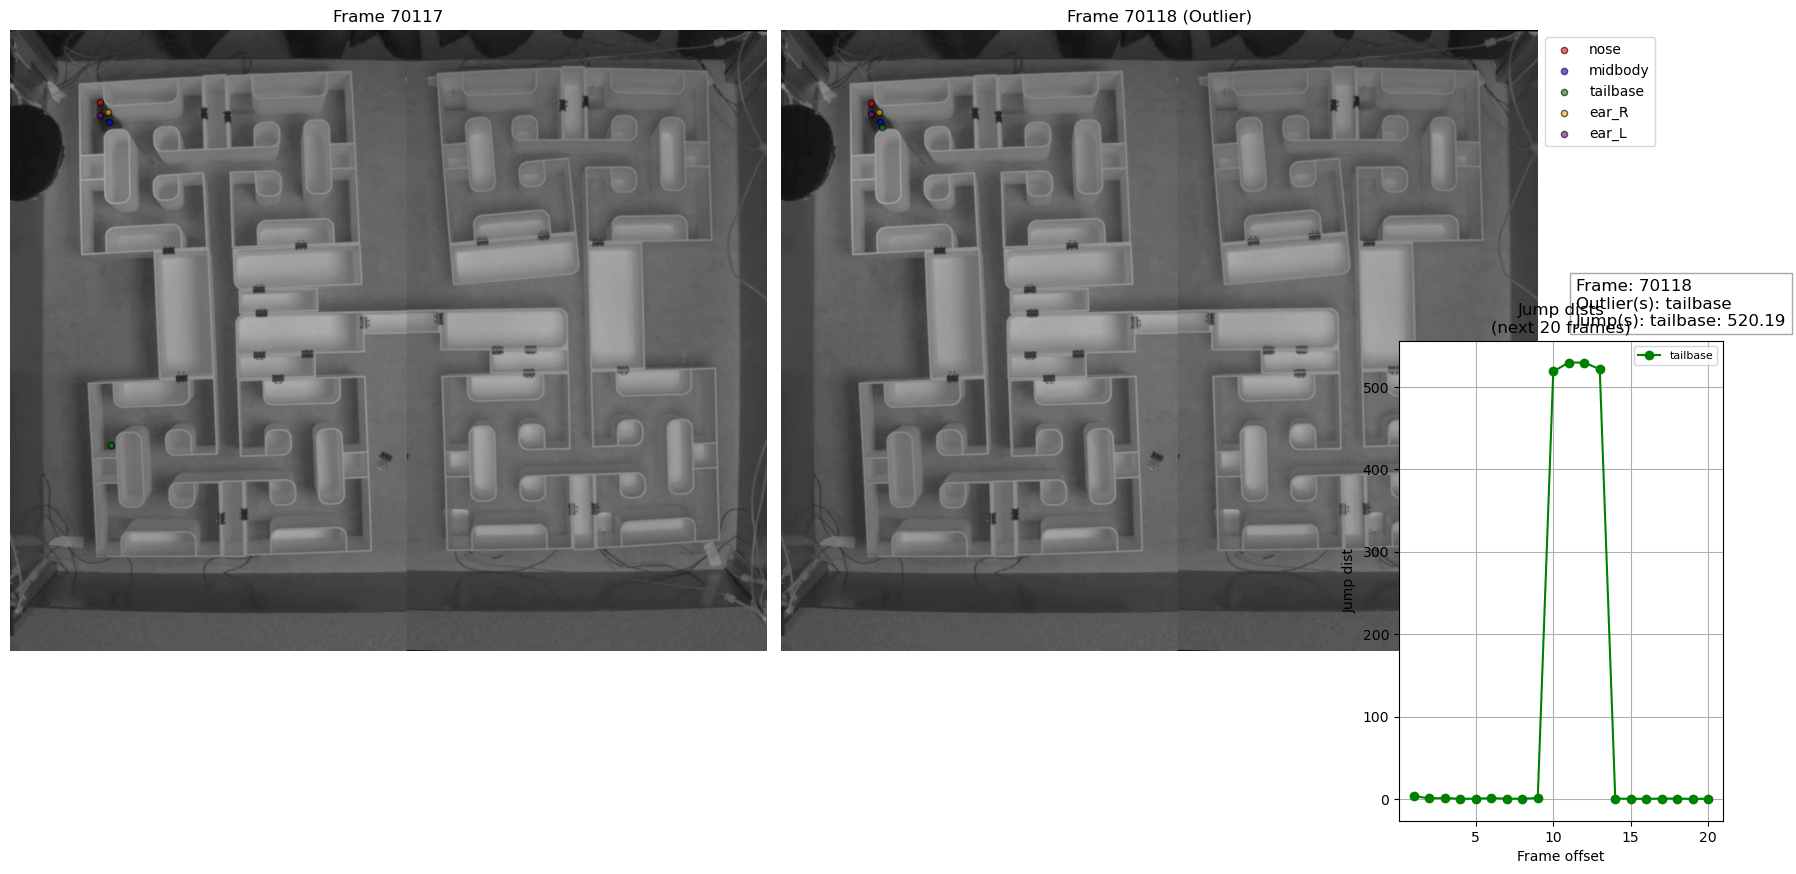

In [70]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

def save_jump_outlier_tifs(
    outlier_df, dlc_df, video_path, bodyparts, color_map, crop_x1=0, crop_y1=0,
    output_folder=r"F:\Shared drives\FinkelsteinLab\People\AlmogMeir\DLC_Tests\jump_outliers",
    start_idx=0, end_idx=None
):
    os.makedirs(output_folder, exist_ok=True)
    cap = cv2.VideoCapture(video_path)
    indices = list(outlier_df.index)
    if end_idx is None:
        end_idx = len(indices)
    for idx in indices[start_idx:end_idx]:
        frame = idx
        prev_frame = frame - 1
        if prev_frame < 0:
            continue

        # Read both frames
        cap.set(cv2.CAP_PROP_POS_FRAMES, prev_frame)
        ret_prev, frame_img_prev = cap.read()
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame)
        ret, frame_img = cap.read()
        if not (ret and ret_prev):
            print(f"Could not read frame {frame} or {prev_frame}")
            continue
        frame_img_prev = cv2.cvtColor(frame_img_prev, cv2.COLOR_BGR2RGB)
        frame_img = cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB)

        # Plot both frames side by side
        fig, axes = plt.subplots(1, 2, figsize=(18, 12))
        for ax, fidx, img, title in zip(
            axes,
            [prev_frame, frame],
            [frame_img_prev, frame_img],
            [f"Frame {prev_frame}", f"Frame {frame} (Outlier)"]
        ):
            ax.imshow(img)
            for bp in bodyparts:
                x = dlc_df.loc[fidx, (bp, 'x')] + crop_x1
                y = dlc_df.loc[fidx, (bp, 'y')] + crop_y1
                ax.scatter(x, y, color=color_map[bp], marker='.', s=80, label=bp, edgecolor='black', alpha=0.6)
            ax.set_title(title)
            ax.axis('off')
        axes[1].legend(loc='upper left', bbox_to_anchor=(1, 1))

        # Outlier bodyparts for this jump
        outlier_bps = outlier_df.loc[frame, 'jumps_outlier_bodypart']
        if isinstance(outlier_bps, pd.Series):
            outlier_bps = outlier_bps.iloc[0]

        # Calculate jump distances for next 20 frames for each outlier bodypart
        hist_data = {}
        for bp in outlier_bps:
            jumps = []
            for offset in range(0, 20):
                f1 = frame + offset
                f2 = frame + offset + 1
                if f2 >= len(dlc_df):
                    jumps.append(np.nan)
                    continue
                x1, y1 = dlc_df.loc[f1, (bp, 'x')], dlc_df.loc[f1, (bp, 'y')]
                x2, y2 = dlc_df.loc[f2, (bp, 'x')], dlc_df.loc[f2, (bp, 'y')]
                jumps.append(np.linalg.norm([x2 - x1, y2 - y1]))
            hist_data[bp] = jumps

        # Metrics text
        jump_vals = []
        for bp in outlier_bps:
            if frame >= 1:
                x1, y1 = dlc_df.loc[prev_frame, (bp, 'x')], dlc_df.loc[prev_frame, (bp, 'y')]
                x2, y2 = dlc_df.loc[frame, (bp, 'x')], dlc_df.loc[frame, (bp, 'y')]
                jump_val = np.linalg.norm([x2 - x1, y2 - y1])
                jump_vals.append(f"{bp}: {jump_val:.2f}")
        info_text = f"Frame: {frame}\nOutlier(s): {', '.join(outlier_bps) if len(outlier_bps) > 0 else 'None'}\nJump(s): {', '.join(jump_vals)}"
        axes[1].text(
            1.05, 0.6, info_text, transform=axes[1].transAxes,
            fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
        )

        # Plot histogram for each outlier bodypart (to the right, smaller y axis)
        if hist_data:
            ax_hist = fig.add_axes([0.78, 0.1, 0.18, 0.4])  # [left, bottom, width, height]
            offsets = list(range(1, 21))
            for bp, jumps in hist_data.items():
                ax_hist.plot(offsets, jumps, marker='o', label=bp, color=color_map[bp])
            ax_hist.set_title("Jump dists\n(next 20 frames)")
            ax_hist.set_xlabel("Frame offset")
            ax_hist.set_ylabel("Jump dist")
            ax_hist.legend(fontsize=8)
            ax_hist.grid(True)

        plt.tight_layout()
        plt.savefig(os.path.join(output_folder, f"jump_outlier_frame_{frame}.tif"), dpi=80, bbox_inches='tight')
        plt.close(fig)
    cap.release()

# Example usage:
save_jump_outlier_tifs(outlier_frames_jumps, dlc_raw_curr_h5, video_path, bodyparts, color_map, crop_x1=100, crop_y1=60, start_idx=1020)

In [55]:
outlier_frames.iloc[1000].name

7291

In [40]:
import cv2
# Prepare color map for bodyparts
color_map = {
    'nose': 'red',
    'midbody': 'blue',
    'tailbase': 'green',
    'ear_R': 'orange',
    'ear_L': 'purple'
}

# Find the n frame index with any outlier in the dist matrix
outlier_idx = int(outlier_frames_jumps.iloc[2500].name)
# outlier_idx = 2097
# 2845 - 2895

# Read the video file (assume video file is in the same folder and named after curr_file, with .mp4 extension)
video_path = r"G:\My Drive\no headstage vids\18L\18L_2025_06_30_14_17_40_stitched.mp4"
cap = cv2.VideoCapture(video_path)

# Get the frame at outlier_idx (assuming outlier_idx matches video frame index)
cap.set(cv2.CAP_PROP_POS_FRAMES, outlier_idx)
ret, frame_img = cap.read()
cap.release()

if not ret:
    raise RuntimeError(f"Could not read frame {outlier_idx} from {video_path}")

# Convert BGR (OpenCV) to RGB (matplotlib)
frame_img = cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB)
# Remove bodypart text, only plot colored dots.
import matplotlib.pyplot as plt

# Get previous frame index
prev_idx = outlier_idx - 1

# Read previous frame from video
cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, prev_idx)
ret_prev, frame_img_prev = cap.read()
cap.release()

if not ret_prev:
    raise RuntimeError(f"Could not read frame {prev_idx} from {video_path}")

# Convert BGR to RGB
frame_img_prev = cv2.cvtColor(frame_img_prev, cv2.COLOR_BGR2RGB)

# Plot both frames side by side
fig, axes = plt.subplots(1, 2, figsize=(18, 12))
for ax, idx, img, title in zip(
    axes,
    [prev_idx, outlier_idx],
    [frame_img_prev, frame_img],
    [f"Frame {prev_idx}", f"Frame {outlier_idx} (Outlier)"]
):
    ax.imshow(img)
    for bp in bodyparts:
        x = dlc_raw_curr_h5.loc[idx, (bp, 'x')] + crop_x1
        y = dlc_raw_curr_h5.loc[idx, (bp, 'y')] + crop_y1
        ax.scatter(x, y, color=color_map[bp], marker='.', s=80, label=bp, edgecolor='black', alpha=0.6)
    ax.set_title(title)
    ax.axis('off')
axes[1].legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()



RuntimeError: Could not read frame 62353 from G:\My Drive\no headstage vids\18L\18L_2025_06_30_14_17_40_stitched.mp4

In [ ]:
# Calculate frames detected as outliers by each method
outlier_dist_idx = set(outlier_frames.index)
outlier_jump_idx = set(outlier_frames_jumps.index)

# Frames detected by both methods
both_methods = outlier_dist_idx & outlier_jump_idx
# Frames detected only by distance
only_dist = outlier_dist_idx - outlier_jump_idx
# Frames detected only by jump
only_jump = outlier_jump_idx - outlier_dist_idx

counts = {
    'Only Distance': len(only_dist),
    'Only Jump': len(only_jump),
    'Both': len(both_methods)
}

plt.figure(figsize=(6, 5))
plt.bar(counts.keys(), counts.values(), color=['#1f77b4', '#ff7f0e', '#2ca02c'])
plt.ylabel('Number of Frames')
plt.show()
plt.tight_layout()
plt.show()
plt.tight_layout()
plt.title('Frames Detected as Outliers by Method')# Calculate frames detected as outliers by each method
outlier_dist_idx = set(outlier_frames.index)
outlier_jump_idx = set(outlier_frames_jumps.index)

# Frames detected by both methods
both_methods = outlier_dist_idx & outlier_jump_idx
# Frames detected only by distance
only_dist = outlier_dist_idx - outlier_jump_idx
# Frames detected only by jump
only_jump = outlier_jump_idx - outlier_dist_idx

counts = {
    'Only Distance': len(only_dist),
    'Only Jump': len(only_jump),
    'Both': len(both_methods)
}

plt.figure(figsize=(6, 5))
plt.bar(counts.keys(), counts.values(), color=['#1f77b4', '#ff7f0e', '#2ca02c'])
plt.ylabel('Number of Frames')
plt.title('Frames Detected as Outliers by Method')

In [128]:
dlc_raw_curr_h5[44190:44192]

nose                          midbody                        \
               x          y likelihood          x          y likelihood   
44190  47.691628  63.783733   0.745233  66.500610  93.903893   0.618453   
44191  47.208405  61.978199   0.766464  65.912796  93.212608   0.618384   

         tailbase                             ear_R                        \
                x           y likelihood          x          y likelihood   
44190   87.864983  103.697166   0.171056  61.031410  78.982643   0.825364   
44191  146.380219  691.740906   0.165677  61.980453  76.179512   0.831601   

           ear_L                       weighted                 \
               x          y likelihood        x   y likelihood   
44190  48.574226  83.490837   0.756945      NaN NaN        NaN   
44191  47.746868  81.067833   0.752924      NaN NaN        NaN   

                    distance_outlier_bodyparts jumps_outlier_bodypart  
                                                                       
44190                                       []                     []  
44191  [nose, midbody, tailbase, ear_R, ear_L]             [tailbase]

In [71]:
import imageio

def save_gif_with_bodyparts(start_idx, end_idx, gif_path, video_path, dlc_df, bodyparts, color_map, crop_x1=0, crop_y1=0):
    """
    Save a GIF of frames from start_idx to end_idx (inclusive), overlaying bodypart markers.
    """
    cap = cv2.VideoCapture(video_path)
    images = []
    for idx in range(start_idx, end_idx + 1):
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame_img = cap.read()
        if not ret:
            print(f"Could not read frame {idx}")
            continue
        frame_img = cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB)
        fig, ax = plt.subplots(figsize=(8, 8))
        ax.imshow(frame_img)
        for bp in bodyparts:
            x = dlc_df.loc[idx, (bp, 'x')] + crop_x1
            y = dlc_df.loc[idx, (bp, 'y')] + crop_y1
            ax.scatter(x, y, color=color_map[bp], marker='.', s=80, edgecolor='black', alpha=0.7)
        ax.axis('off')
        fig.tight_layout(pad=0)
        # Draw canvas and convert to numpy array (RGBA)
        fig.canvas.draw()
        img_arr = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8)
        img_arr = img_arr.reshape(fig.canvas.get_width_height()[::-1] + (4,))
        # Convert RGBA to RGB
        img_arr = img_arr[..., :3]
        images.append(img_arr)
        plt.close(fig)
    cap.release()
    imageio.mimsave(gif_path, images, duration=0.1)  # duration in seconds per frame

# Example usage:
save_gif_with_bodyparts(2845, 2895, r"C:\Users\Almog\Documents\GitHub\MazeToGraph\test.gif", video_path, dlc_raw_curr_h5, bodyparts, color_map, crop_x1, crop_y1)

In [167]:
from collections import Counter

# Count occurrences of each unique list in the 'distance_outlier_bodyparts' column

outlier_lists = dlc_raw_curr_h5['distance_outlier_bodyparts']
outlier_list_counts = Counter(tuple(lst) for lst in outlier_lists)
print(outlier_list_counts)

Counter({(): 43276, ('nose', 'midbody', 'tailbase', 'ear_R', 'ear_L'): 33349, ('tailbase',): 540, ('midbody', 'tailbase', 'ear_R', 'ear_L'): 277, ('nose', 'midbody', 'ear_R', 'ear_L'): 32, ('tailbase', 'ear_R', 'ear_L'): 26, ('nose', 'ear_R', 'ear_L'): 15, ('tailbase', 'ear_R'): 8, ('nose',): 7, ('midbody',): 6, ('ear_L',): 4, ('midbody', 'tailbase'): 3, ('midbody', 'ear_R', 'ear_L'): 2, ('tailbase', 'ear_L'): 2, ('midbody', 'tailbase', 'ear_R'): 1, ('ear_R', 'ear_L'): 1})


In [168]:
# Save all rows where 'distance_outlier_bodyparts' equals ('nose', 'midbody', 'tailbase', 'ear_R', 'ear_L')
all_outlier_tuple = ('nose', 'midbody', 'tailbase', 'ear_R', 'ear_L')
all_outlier_rows_df = dlc_raw_curr_h5[dlc_raw_curr_h5['distance_outlier_bodyparts'].apply(lambda x: tuple(x) == all_outlier_tuple)].copy()

In [174]:
all_outlier_rows_df

nose                            midbody                         \
                x           y likelihood           x           y likelihood   
0        7.488315  992.001404   0.303407   33.275558  142.523743   0.433099   
1        7.777886  991.618652   0.294189   33.528011  142.871521   0.422946   
2        7.536671  991.916016   0.311148   33.476772  142.799011   0.426724   
3        7.410993  992.055786   0.316681   33.491104  142.838318   0.425394   
4        7.614246  991.820984   0.290845   33.559502  142.816833   0.427544   
...           ...         ...        ...         ...         ...        ...   
77541  463.697113  691.371765   0.391740  420.915710  704.838928   0.779717   
77542  468.087799  692.165466   0.552414  423.039001  705.609741   0.778473   
77543  470.657257  695.543945   0.596789  425.237976  706.769348   0.718784   
77545  477.271088  701.304565   0.525462  434.408203  706.319641   0.917628   
77546  481.044495  704.245117   0.672527  437.373016  705.286499   0.871607   

          tailbase                               ear_R                         \
                 x           y likelihood            x           y likelihood   
0        13.518434  275.254608   0.469136  1230.934082  932.431091   0.371297   
1        13.458936  275.289673   0.472990  1229.705444  937.662720   0.280459   
2      1131.352417   37.682228   0.463230  1229.682617  937.602661   0.287565   
3        13.631626  274.874054   0.457493  1229.805908  937.543701   0.285610   
4      1130.845947   37.377689   0.495043  1229.729004  937.585022   0.297318   
...            ...         ...        ...          ...         ...        ...   
77541  1008.377930   21.676056   0.584390   458.792480  702.669373   0.416325   
77542  1008.443176   21.862314   0.581326   459.608704  706.032471   0.590915   
77543  1008.395081   21.660919   0.584182   459.302277  708.442627   0.677120   
77545  1008.447571   21.392534   0.579608   463.772308  710.548889   0.569700   
77546  1008.433838   21.303625   0.583089   466.408722  710.974243   0.756703   

             ear_L                        weighted                 \
                 x           y likelihood        x   y likelihood   
0      1245.637573  940.105164   0.267320      NaN NaN        NaN   
1      1245.890991  940.448120   0.232109      NaN NaN        NaN   
2      1245.779053  940.553162   0.237785      NaN NaN        NaN   
3      1245.842896  940.433167   0.228468      NaN NaN        NaN   
4      1245.751343  940.576172   0.238390      NaN NaN        NaN   
...            ...         ...        ...      ...  ..        ...   
77541   449.118408  695.006042   0.400351      NaN NaN        NaN   
77542   453.552216  695.751770   0.627464      NaN NaN        NaN   
77543   455.051178  696.703186   0.664602      NaN NaN        NaN   
77545   463.153320  698.239563   0.593893      NaN NaN        NaN   
77546   466.448578  697.515137   0.763159      NaN NaN        NaN   

                    distance_outlier_bodyparts  
                                                
0      [nose, midbody, tailbase, ear_R, ear_L]  
1      [nose, midbody, tailbase, ear_R, ear_L]  
2      [nose, midbody, tailbase, ear_R, ear_L]  
3      [nose, midbody, tailbase, ear_R, ear_L]  
4      [nose, midbody, tailbase, ear_R, ear_L]  
...                                        ...  
77541  [nose, midbody, tailbase, ear_R, ear_L]  
77542  [nose, midbody, tailbase, ear_R, ear_L]  
77543  [nose, midbody, tailbase, ear_R, ear_L]  
77545  [nose, midbody, tailbase, ear_R, ear_L]  
77546  [nose, midbody, tailbase, ear_R, ear_L]  

[33349 rows x 19 columns]

In [187]:
all_outlier_rows_df.iloc[12000]['nose']

x             1232.523926
y              952.849426
likelihood       0.378933
Name: 35486, dtype: object

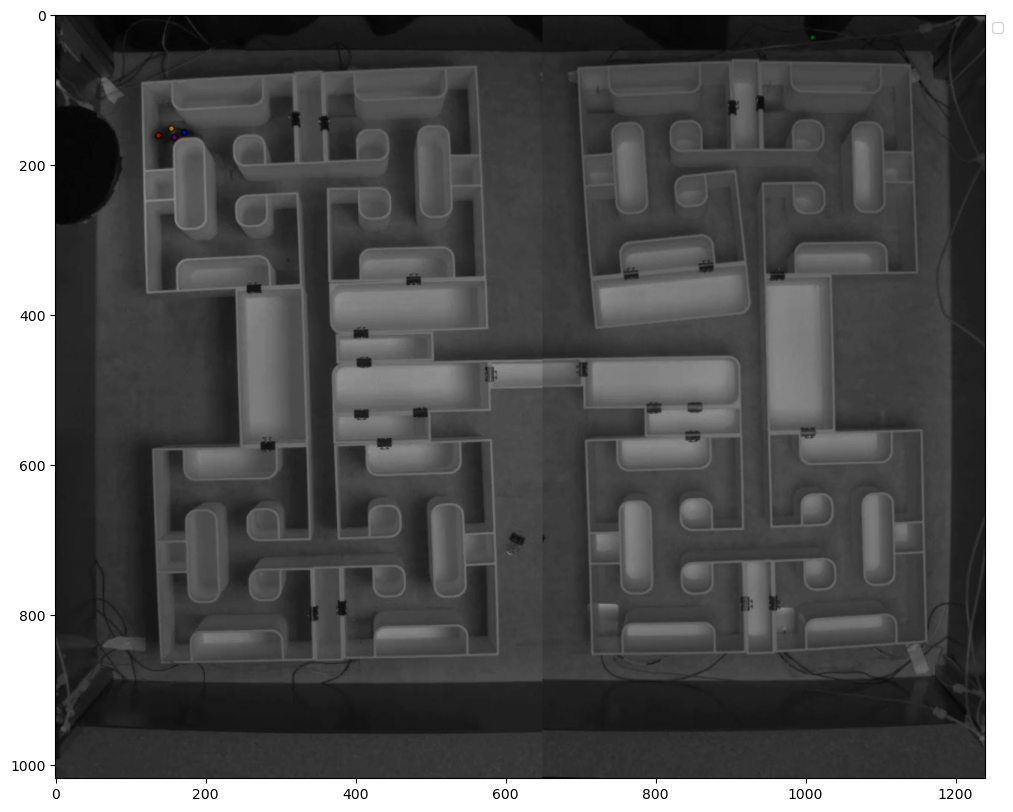

In [ ]:
import cv2
# Prepare color map for bodyparts
color_map = {
    'nose': 'red',
    'midbody': 'blue',
    'tailbase': 'green',
    'ear_R': 'orange',
    'ear_L': 'purple'
}

# Find the n frame index with any outlier in the dist matrix
outlier_idx = 2000

# Read the video file (assume video file is in the same folder and named after curr_file, with .mp4 extension)
video_path = r"G:\My Drive\no headstage vids\18R\18R_2025_06_30_11_25_03_stitched.mp4"
cap = cv2.VideoCapture(video_path)

# Get the frame at outlier_idx (assuming outlier_idx matches video frame index)
cap.set(cv2.CAP_PROP_POS_FRAMES, all_outlier_rows_df.iloc[outlier_idx].name)
ret, frame_img = cap.read()
cap.release()

if not ret:
    raise RuntimeError(f"Could not read frame {outlier_idx} from {video_path}")

# Convert BGR (OpenCV) to RGB (matplotlib)
frame_img = cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB)
# Remove bodypart text, only plot colored dots.
# Collect handles and labels for legend (only for outlier bodyparts)
handles = []
labels = []

plt.figure(figsize=(12, 12))
plt.imshow(frame_img)
for bp in bodyparts:
    x = all_outlier_rows_df.iloc[outlier_idx][(bp, 'x')]
    y = all_outlier_rows_df.iloc[outlier_idx][(bp, 'y')]
    sc = plt.scatter(x, y, color=color_map[bp], marker='.', label=bp, 
                     s=60, edgecolor='black' if is_out else None, alpha=0.6)

plt.legend(handles, labels, loc='upper left', bbox_to_anchor=(1, 1))

In [191]:
outlier_frames_df.iloc[2000]

nose            x                6.323112
                y              992.286560
                likelihood       0.434750
midbody         x               34.756508
                y              142.648193
                likelihood       0.481656
tailbase        x               12.499631
                y              275.167938
                likelihood       0.454345
ear_R           x              190.506531
                y              305.359283
                likelihood       0.589823
ear_L           x              205.624435
                y              304.168457
                likelihood       0.750135
weighted        x                     NaN
                y                     NaN
                likelihood            NaN
original_index                2159.000000
Name: 2159, dtype: float64

In [194]:
dlc_raw_curr_h5.iloc[2159]

nose                        x                                            6.323112
                            y                                           992.28656
                            likelihood                                    0.43475
midbody                     x                                           34.756508
                            y                                          142.648193
                            likelihood                                   0.481656
tailbase                    x                                           12.499631
                            y                                          275.167938
                            likelihood                                   0.454345
ear_R                       x                                          190.506531
                            y                                          305.359283
                            likelihood                                   0.589823
ear_L           

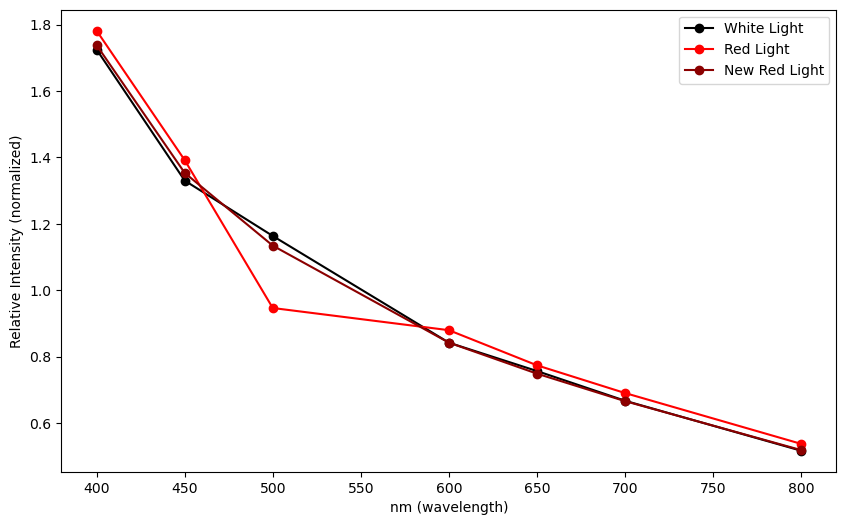

In [ ]:
x = [400, 450, 500, 600, 650, 700, 800]
new_white = [177.2, 139.2, 117.2, 86.7, 77.2, 68.7, 53.4]
white = [212, 163.5, 143, 103.5, 93, 82, 63.5]
red = [64, 50, 34, 31.6, 27.8, 24.8, 19.3]
new_red = [357, 278, 233, 173, 153.8, 136.8, 106.5]

# white_norm = [v / max(white) for v in white]
# red_norm = [v / max(red) for v in red]
# new_red_norm = [v / max(new_red) for v in new_red]

white_norm = [v / np.mean(white) for v in white]
red_norm = [v / np.mean(red) for v in red]
new_red_norm = [v / np.mean(new_red) for v in new_red]

plt.figure(figsize=(10, 6))
plt.plot(x, white_norm, marker='o', label='White Light', color='black')
plt.plot(x, red_norm, marker='o', label='Red Light', color='red')
plt.plot(x, new_red_norm, marker='o', label='New Red Light', color='darkred')

# plt.plot(x, white, marker='o', label='White Light', color='black')
# plt.plot(x, red, marker='o', label='Red Light', color='red')
# plt.plot(x, new_red, marker='o', label='New Red Light', color='darkred')

plt.xlabel("nm (wavelength)")
plt.ylabel("Relative Intensity (normalized)")

plt.legend()